# Driver identity — seat pace and tyre style (F17)

Two numbers per driver, both out of fits the battery already runs.

**Seat pace** is the per-driver fixed effect in the E-10 joint regression. It was always
estimated and always thrown away: `t0_s` absorbed its mean and `sigma_driver_s` kept its
spread, which is what an unnamed grid draws from. Here it is persisted, centred, so `t0_s`
keeps its meaning and the spread is untouched.

**Tyre style** is a multiplier on the pooled degradation amplitude — the least-squares
slope of a driver's partial residual on the degradation the shared curve predicts for that
lap. `degradation.py` refuses a per-driver *curve* for a real reason: one driver's stints
cannot identify a power law. One number can be identified, and that is what this fits.

### Read both as seat effects, not skill

Era 2024 pools 2022–2025. Session fixed effects absorb per-session mean pace, so what
survives in a driver's coefficient is their offset within their own sessions, across
whatever cars they drove in those seasons. It is the seat. `configs/drivers.yaml` records
the lap count and the season list beside every value so the question "how do you know
Verstappen's number" has an answer at the leaf.

The same caveat applies to `deg_mult`, more strongly if anything: tyre usage is dominated
by the car's aerodynamics and suspension.

In [1]:
import numpy as np
import pandas as pd

from senna import config
from senna.data.db import database_url, engine_for
from senna.physics.fits import frames, plots
from senna.physics.fits.degradation import fit_degradation
from senna.physics.fits.fuel import session_fuel
from senna.physics.fits.joint_pace import age_partial_residuals, fit_joint_pace
from senna.physics.fits.tyre_style import deg_prediction_s, fit_deg_multipliers

fits_cfg = config.load("fits")
split = config.load("data_split")
rounds = config.get(split, "calibration_rounds")
driver_cfg = config.get(fits_cfg, "driver_identity")
vif_max = float(config.get(fits_cfg, "joint_pace.vif_max"))
sc_burn = float(config.get(fits_cfg, "fuel.sc_burn_factor"))
deg_cfg = config.get(fits_cfg, "degradation")
driver_cfg

{'min_laps_for_seat_pace': 30,
 'min_stints_for_deg_mult': 12,
 'max_rel_se_for_deg_mult': 0.1}

## The inputs, one era at a time

Same path the battery takes: dry slick laps per circuit-era, the joint fit, then its partial
residuals. Nothing here re-implements a fitter — a notebook that fitted differently from the
battery would be documenting a model the simulator does not run.

In [2]:
ERA = "2024"  # the four-season era; switch to "2026" for the calibration rounds

engine = engine_for(database_url())
async def _load():
    async with engine.connect() as conn:
        index = await frames.circuit_index(conn, rounds)
        by_circuit = {}
        for slug in sorted(index.loc[index["era"] == ERA, "slug"].unique()):
            event = index.loc[index["slug"] == slug, "event_name"].iloc[0]
            laps = await frames.pace_laps(conn, event, ERA, rounds)
            laps = laps[laps["compound"].isin(("SOFT", "MEDIUM", "HARD"))]
            if not laps.empty:
                by_circuit[slug] = laps
        return index, by_circuit

index, laps_by_circuit = await _load()  # noqa: F704 — notebooks run in a live loop
len(laps_by_circuit)

25

In [3]:
joint, residuals, deg = {}, {}, {}
for slug, laps in laps_by_circuit.items():
    fuel_kg = session_fuel(laps, config.get(config.load(f"physics_{ERA}"), "mass.race_fuel_kg"),
                           sc_burn)
    fit = fit_joint_pace(laps, fuel_kg, vif_max=vif_max, calibration_rounds=rounds)
    joint[slug] = fit
    residuals[slug] = age_partial_residuals(laps, fuel_kg, calibration_rounds=rounds)
    deg[slug] = fit_degradation(
        residuals[slug], fit.t0_s,
        bounds=([deg_cfg["curve_bounds"]["a"][0], deg_cfg["curve_bounds"]["b"][0]],
                [deg_cfg["curve_bounds"]["a"][1], deg_cfg["curve_bounds"]["b"][1]]),
        min_laps=deg_cfg["min_laps"], min_stints=deg_cfg["min_stints"],
        min_drivers=deg_cfg["min_drivers"], min_max_age=deg_cfg["min_max_age"],
        p0=deg_cfg["curve_p0"], maxfev=deg_cfg["curve_maxfev"],
    )
print(f"{len(joint)} circuits, {sum(len(f.driver_effects_s) for f in joint.values())} driver cells")

25 circuits, 652 driver cells


## Seat pace: the two properties that are silently wrong if broken

The effects are centred, so they sum to zero and their spread equals the `sigma_driver_s`
that same fit reports. Centring is what lets a named lineup and the random draw be the same
distribution — which is what keeps M1 measuring strategy rather than car.

In [4]:
checks = pd.DataFrame([
    {"circuit": slug,
     "drivers": len(fit.driver_effects_s),
     "sum_s": sum(fit.driver_effects_s.values()),
     "std_s": np.std(list(fit.driver_effects_s.values()), ddof=1),
     "sigma_driver_s": fit.sigma_driver_s}
    for slug, fit in joint.items()
]).set_index("circuit")
checks["agrees"] = np.isclose(checks["std_s"], checks["sigma_driver_s"])
assert checks["agrees"].all() and np.allclose(checks["sum_s"], 0.0, atol=1e-9)
checks.head(10)

,drivers,sum_s,std_s,sigma_driver_s,agrees
circuit,,,,,
abu_dhabi_grand_prix,30,4.996004e-16,0.527108,0.527108,True
australian_grand_prix,22,4.440892e-16,0.709511,0.709511,True
austrian_grand_prix,28,-1.110223e-15,0.511445,0.511445,True
azerbaijan_grand_prix,30,-2.220446e-16,0.738886,0.738886,True
bahrain_grand_prix,29,1.665335e-16,0.657115,0.657115,True
belgian_grand_prix,29,-6.661338e-16,0.691882,0.691882,True
british_grand_prix,20,4.440892e-16,0.489434,0.489434,True
canadian_grand_prix,24,1.665335e-16,0.577744,0.577744,True
chinese_grand_prix,26,2.220446e-16,0.528317,0.528317,True


### How thin is a thin cell?

`min_laps_for_seat_pace` is the gate on publishing a driver's number *at one circuit*. Below
it the cell is dropped and the driver keeps their lap-weighted mean over the circuits that
did clear — the second rung of the resolver's ladder. The gate is set where it refuses the
tail without gutting coverage.

In [5]:
cells = pd.DataFrame([
    {"circuit": slug, "driver": code, "laps": fit.driver_laps.get(code, 0),
     "effect_s": effect_s}
    for slug, fit in joint.items() for code, effect_s in fit.driver_effects_s.items()
])
gate = int(driver_cfg["min_laps_for_seat_pace"])
print(f"{len(cells)} cells, {(cells['laps'] >= gate).sum()} clear the {gate}-lap gate")
print(cells["laps"].describe()[["min", "25%", "50%", "max"]].to_string())
cells.nsmallest(8, "laps")

652 cells, 628 clear the 30-lap gate
min      1.0
25%     55.0
50%     93.0
max    240.0


,circuit,driver,laps,effect_s
377,japanese_grand_prix,BOT,1,21.572490
477,monaco_grand_prix,GAS,3,0.580225
206,canadian_grand_prix,SAR,5,0.575254
178,british_grand_prix,OCO,7,0.259182
388,japanese_grand_prix,PER,7,-0.474723
87,azerbaijan_grand_prix,DEV,8,0.603680
370,italian_grand_prix,VET,9,0.369231
392,japanese_grand_prix,SAR,11,-0.262367


## Tyre style: sizing the precision gate

Two decisions live in this section, and both were made here rather than guessed.

**The standard error is clustered by stint.** A set that runs hot is slow for its whole
life, so the lap-level error bar treats eighteen correlated laps as eighteen independent
observations. The comparison below is why a gate built on the naive number would pass
everyone.

In [6]:
pooled = pd.concat([
    r.assign(predicted_deg_s=deg_prediction_s(r, deg[slug], joint[slug].t0_s))
    for slug, r in residuals.items() if deg.get(slug)
], ignore_index=True)

def naive_se(rows):
    d = rows["predicted_deg_s"].to_numpy(float)
    r = rows["pace_residual_s"].to_numpy(float)
    bread = float(d @ d)
    if bread <= 0:
        return np.nan
    e = r - (float(r @ d) / bread) * d
    return float(np.sqrt(float(e @ e) / max(len(rows) - 1, 1)) / np.sqrt(bread))

style = fit_deg_multipliers(pooled, min_stints=int(driver_cfg["min_stints_for_deg_mult"]),
                            max_rel_se=float(driver_cfg["max_rel_se_for_deg_mult"]))
compare = pd.DataFrame([
    {"driver": code, "mult": fit.mult, "clustered_se": fit.se,
     "naive_se": naive_se(pooled[pooled["driver"] == code]),
     "rel_se": fit.rel_se, "n_stints": fit.n_stints, "identified": fit.identified}
    for code, fit in style.items()
]).set_index("driver").sort_values("rel_se")
compare["inflation"] = compare["clustered_se"] / compare["naive_se"]
print(f"clustered / naive standard error: median {compare['inflation'].median():.1f}x")
compare

clustered / naive standard error: median 2.3x


,mult,clustered_se,naive_se,rel_se,n_stints,identified,inflation
driver,,,,,,,
LAW,0.982803,0.025100,0.017905,0.025539,72,True,1.401838
TSU,0.977920,0.026652,0.012840,0.027254,168,True,2.075685
HAD,0.994121,0.028472,0.017889,0.028641,49,True,1.591596
VER,1.024260,0.030114,0.011359,0.029400,180,True,2.651027
HUL,1.019826,0.030447,0.014172,0.029856,142,True,2.148400
GAS,1.000588,0.031365,0.013694,0.031347,174,True,2.290379
RUS,0.978367,0.031195,0.011845,0.031884,189,True,2.633476
LEC,1.008028,0.033865,0.011958,0.033596,175,True,2.831970
STR,0.982422,0.034026,0.013627,0.034635,176,True,2.496878


The multipliers are normalised to a lap-weighted mean of exactly 1.0. Without it,
naming a full grid would move every stint length in the race at once instead of
redistributing wear between seats — the pooled amplitude was fitted on all these drivers
together, so their average is the curve by construction.

In [7]:
laps_by_code = {code: fit.n_laps for code, fit in style.items()}
weighted = sum(laps_by_code[c] * f.mult for c, f in style.items()) / sum(laps_by_code.values())
identified = sum(f.identified for f in style.values())
print(f"lap-weighted mean multiplier: {weighted:.12f}")
print(f"identified: {identified} of {len(style)} drivers at "
      f"max_rel_se={driver_cfg['max_rel_se_for_deg_mult']}")
assert np.isclose(weighted, 1.0)

lap-weighted mean multiplier: 1.000000000000
identified: 31 of 31 drivers at max_rel_se=0.1


### Where the gate sits

The sweep below is the sizing argument for `max_rel_se_for_deg_mult`. A threshold that
identifies everyone is not a gate, and one that identifies nobody throws away a real
signal; the value shipped refuses the thin seats and keeps the ones with an era of running
behind them.

In [8]:
sweep = pd.DataFrame([
    {"max_rel_se": t,
     "identified": int((compare["rel_se"] <= t).sum()),
     "of": len(compare)}
    for t in (0.02, 0.05, 0.10, 0.15, 0.25, 0.50)
]).set_index("max_rel_se")
sweep

,identified,of
max_rel_se,,
0.02,0,31
0.05,23,31
0.10,31,31
0.15,31,31
0.25,31,31
0.50,31,31


PosixPath('/Users/saad/senna/docs/fits/driver_identity/residuals_2024.png')

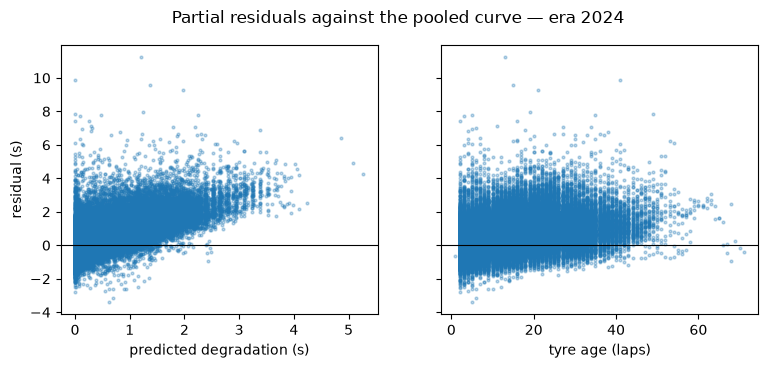

In [9]:
fig = plots.residual_panel(
    pooled["pace_residual_s"],
    {"predicted degradation (s)": pooled["predicted_deg_s"],
     "tyre age (laps)": pooled["tyre_life"]},
    f"Partial residuals against the pooled curve — era {ERA}",
)
plots.save_figure(fig, "driver_identity", f"residuals_{ERA}")

## What the table says

The spread below is the deliverable. A seat effect near zero is a driver at the field
average for those seasons, not a driver with no talent — and a multiplier at exactly 1.0
with `identified: false` is the honest "I don't know", which is the answer the interpretability
contract cares most about being able to give.

In [10]:
table = pd.DataFrame([
    {"driver": code,
     "seat_pace_mean_s": np.average(
         [e for s, e in zip(cells.loc[cells['driver'] == code, 'circuit'],
                            cells.loc[cells['driver'] == code, 'effect_s'], strict=False)],
         weights=cells.loc[cells["driver"] == code, "laps"]),
     "laps": int(cells.loc[cells["driver"] == code, "laps"].sum()),
     "deg_mult": style[code].mult if code in style else np.nan,
     "style_identified": style[code].identified if code in style else False}
    for code in sorted(cells["driver"].unique())
]).set_index("driver").sort_values("seat_pace_mean_s")
table

,seat_pace_mean_s,laps,deg_mult,style_identified
driver,,,,
VER,-1.150703,3423,1.024260,True
LEC,-0.861078,3381,1.008028,True
PIA,-0.748387,2586,0.967905,True
PER,-0.740504,2328,1.030247,True
NOR,-0.671328,3451,0.972382,True
RUS,-0.645517,3497,0.978367,True
HAM,-0.602281,3304,0.998117,True
SAI,-0.586524,3164,1.003323,True
ANT,-0.371477,934,0.938566,True


### Is `deg_mult` just seat pace again?

Partly, and the number below is how much. Both quantities carry the car, so a slower seat
wearing its tyres harder is the expected shape rather than a surprise — bad cars slide more.
The question is whether the multiplier is a *restatement* of pace, which would make it a
second copy of one measurement wearing two names.

It is not. The correlation is moderate, so most of the variance in tyre style is something
other than how quick the seat was, and that residual is what a named race actually uses.

In [11]:
paired = table.dropna(subset=["deg_mult"])
r = float(np.corrcoef(paired["seat_pace_mean_s"], paired["deg_mult"])[0, 1])
print(f"corr(seat_pace_mean_s, deg_mult) = {r:+.3f}  ->  r^2 = {r**2:.3f}")
print(f"{1 - r**2:.0%} of the tyre-style spread is not explained by seat pace")
committed_sigma_s = np.median([
    block["sigma_driver_s"]
    for circuit in config.load("physics_params")["circuits"].values()
    for era_key, block in (circuit.get("joint_pace") or {}).items()
    if str(era_key) == ERA
])
# the persisted spread must land near what an unnamed grid draws from, or a named race
# and a drawn one would not be the same distribution and M1 would stop comparing like
# with like. Averaging a driver over circuits shrinks it slightly, which is expected.
print(f"sd(seat_pace_mean_s) = {paired['seat_pace_mean_s'].std(ddof=1):.3f} s "
      f"against a committed median sigma_driver_s of {committed_sigma_s:.3f} s")

corr(seat_pace_mean_s, deg_mult) = +0.402  ->  r^2 = 0.161
84% of the tyre-style spread is not explained by seat pace


sd(seat_pace_mean_s) = 0.534 s against a committed median sigma_driver_s of 0.587 s


In [12]:
await engine.dispose()  # noqa: F704